In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pixell import enmap, utils, enplot, reproject, wcsutils
import szifi
from scipy import ndimage
from tqdm import tqdm

from scipy.spatial.distance import cdist
import os
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
import gzip
from tqdm import tqdm

from pixell import enmap, utils, enplot, reproject
import szifi

import sys
sys.path.append("/shared_home/Ziyang/Cluster_Finder/")
from useful_code import *
from func_get_cata import *
import copy
import pymaster as nmt

In [3]:
seed = 0
cmb_seed = 0
tile_len = 8
mass_name = "lowmass"
lmin = 1; lmax = 20000
q_th_noise = 4.0

cov_type = "anisotropic_gaussian"
kernel_shape = 3
it = 1
apotype = "C2"
aposcale = 25

noise_name = "mss2"

NN = int(tile_len/2*60/0.5)

In [7]:

res_dir = mass_name+"_"+noise_name+"_"+cov_type+str(kernel_shape)+"_"+str(lmin)+"_"+str(lmax)+"_apo"+apotype+"_"+str(aposcale)+"/"
map_name = str(cmb_seed)+"_"+mass_name+"_"+noise_name

field_id = "sq8deg_7_0"
it = 1
j = 0
# q_map, snr
snr_maps_path = "/shared_home/Ziyang/data/ten_realizations/snr_maps/"+res_dir
snr_map_file = snr_maps_path + "/" + f"snr_map_{str(map_name)}_t{field_id}" + "_q_" + str(it) + "_" + str(j) + ".npy.gz"
with gzip.open(snr_map_file, 'rb') as f:
    snr_data = np.load(f)
    
#std
path_cata = "/shared_home/Ziyang/data/ten_realizations/catalogues_car/"+res_dir
name = "so_it_car_find_" + map_name 
cat_file = os.path.join(path_cata, f"{name}_{field_id}.npy")
cat = np.load(cat_file, allow_pickle=1)[()]
std_fid = cat[field_id].sigma_vec["find_"+str(it)][j]

In [15]:
snr_data.shape, NN

((1200, 1200), 480)

In [37]:
def get_clipped_std(ymap, sigmaClip=5.0):
    Mean = np.mean(ymap)
    RMS = np.std(ymap)
    for i in range(10):
        # print(RMS)
        mask=np.less(abs(ymap-Mean), abs(sigmaClip*RMS))
        Mean = np.mean(ymap[mask])
        RMS = np.std(ymap[mask])
        
    return RMS

get_clipped_std(snr_data)

0.985738387100961

In [46]:
for i1 in range(len(aposcales)):
    aposcale = aposcales[i1]
    mask_apo = nmt.mask_apodization_flat( mask_bin, tile_len+2, tile_len+2, aposcale*pixel_len, apotype="C2")
    print(np.sum(mask_apo**2)/np.sum(mask_bin**2),np.sum(mask_apo)/np.sum(mask_bin))

0.9999666973847787 0.9999833069283952
0.9799285349533395 0.9842644104827478
0.9691529718004858 0.97562886326323
0.9584438856664239 0.9670397217007705
0.9477993403270603 0.9584960205509578
0.937218437039292 0.9499973102884511
0.875089795645148 0.8999599998388688
0.8152849762499875 0.851558707565507


In [52]:
all_field_ids = ['sq8deg_7_0', 'sq8deg_7_1', 'sq8deg_7_2', 'sq8deg_7_3', 'sq8deg_7_4', 'sq8deg_7_5', 'sq8deg_7_6', 'sq8deg_7_7', 'sq8deg_7_8', 'sq8deg_7_9']
aposcales = np.array([1, 10, 15, 20, 25, 30, 60, 90])
std_fid = np.zeros((len(aposcales), len(all_field_ids)))
std_tile = np.zeros((len(aposcales), len(all_field_ids)))
std_tile_buffer = np.zeros((len(aposcales), len(all_field_ids)))
std_fid_collected = np.zeros((len(aposcales), len(all_field_ids)))

std_tile_clipped = np.zeros((len(aposcales), len(all_field_ids)))
std_tile_buffer_clipped = np.zeros((len(aposcales), len(all_field_ids)))


mask_bin = np.ones(snr_data.shape)
mask_bin[:, 0] = 0; mask_bin[:, -1] = 0; mask_bin[0, :] = 0; mask_bin[-1, :] = 0

for i1 in range(len(aposcales)):
    aposcale = aposcales[i1]
    mask_apo = nmt.mask_apodization_flat( mask_bin, tile_len+2, tile_len+2, aposcale*pixel_len, apotype="C2")
    f_sky = np.sum(mask_apo)/np.sum(mask_bin)
    res_dir = mass_name+"_"+noise_name+"_"+cov_type+str(kernel_shape)+"_"+str(lmin)+"_"+str(lmax)+"_apo"+apotype+"_"+str(aposcale)+"/"

    # print("\n", aposcale)
    for i2 in range(len(all_field_ids)):
        field_id = all_field_ids[i2]
        
        snr_maps_path = "/shared_home/Ziyang/data/ten_realizations/snr_maps/"+res_dir
        snr_map_file = snr_maps_path + "/" + f"snr_map_{str(map_name)}_t{field_id}" + "_q_" + str(it) + "_" + str(j) + ".npy.gz"
        with gzip.open(snr_map_file, 'rb') as f:
            snr_data = np.load(f)
    
        path_cata = "/shared_home/Ziyang/data/ten_realizations/catalogues_car/"+res_dir
        name = "so_it_car_find_" + map_name 
        cat_file = os.path.join(path_cata, f"{name}_{field_id}.npy")
        cat = np.load(cat_file, allow_pickle=1)[()]
        std_fid[i1, i2] = cat[field_id].sigma_vec["find_"+str(it)][j]
        std_fid_collected[i1, i2] = std_fid[i1, i2]/f_sky
        
        std_tile[i1, i2] = np.std(snr_data[snr_data.shape[0]//2-NN:snr_data.shape[0]//2+NN, snr_data.shape[1]//2-NN:snr_data.shape[1]//2+NN]*std_fid[i1, i2])
        std_tile_buffer[i1, i2] = np.std(snr_data*std_fid[i1, i2])

        std_tile_clipped[i1, i2] = get_clipped_std(snr_data[snr_data.shape[0]//2-NN:snr_data.shape[0]//2+NN, snr_data.shape[1]//2-NN:snr_data.shape[1]//2+NN]*std_fid[i1, i2])
        std_tile_buffer_clipped[i1, i2] = get_clipped_std(snr_data*std_fid[i1, i2])

        # print(field_id+":", std_fid,np.std(snr_data*std_fid), np.std(snr_data[NN:-NN, NN:-NN]*std_fid),)

        



    

Text(0, 0.5, '$\\sigma_y$')

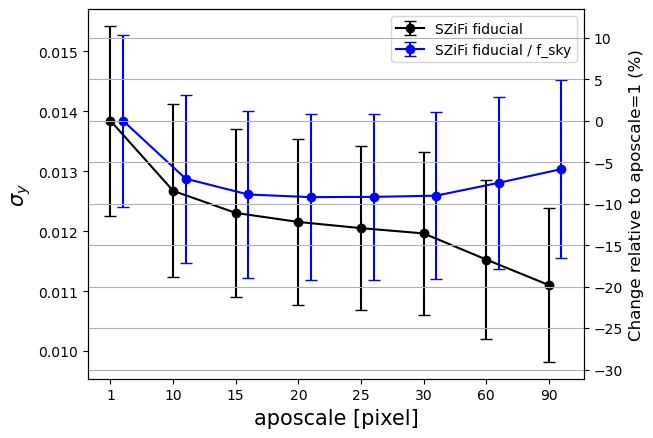

In [55]:
fig, ax = plt.subplots()
aposcales = np.array([1, 10, 15, 20, 25, 30, 60, 90])
ax.errorbar(np.arange(len(aposcales)), np.mean(std_fid, axis = 1), yerr = np.std(std_fid, axis = 1),
           ls = "-", fmt="ko", capsize = 4, label = "SZiFi fiducial")
# ax.errorbar(np.arange(len(aposcales))+.1, np.mean(std_tile, axis = 1), yerr = np.std(std_tile, axis = 1),
#            ls = "-", fmt="ro", capsize = 4, label = "tile")
# ax.errorbar(np.arange(len(aposcales))+.2, np.mean(std_tile_buffer, axis = 1), yerr = np.std(std_tile_buffer, axis = 1),
#            ls = "-", fmt="go", capsize = 4, label = "tile + buffur")
ax.errorbar(np.arange(len(aposcales))+.2, np.mean(std_fid_collected, axis = 1), yerr = np.std(std_tile_buffer_collected, axis = 1),
           ls = "-", fmt="bo", capsize = 4, label = "SZiFi fiducial / f_sky")
# ax.errorbar(np.arange(len(aposcales))+.1, np.mean(std_tile_clipped, axis = 1), yerr = np.std(std_tile_clipped, axis = 1),
#            ls = ":", fmt="mo", capsize = 4, label = "tile (clipped)")
# ax.errorbar(np.arange(len(aposcales))+.2, np.mean(std_tile_buffer_clipped, axis = 1), yerr = np.std(std_tile_buffer_clipped, axis = 1),
           # ls = ":", fmt="yo", capsize = 4, label = "tile + buffur (clipped)")

ax2 = ax.twinx()
y0 =  np.mean(std_fid, axis = 1)[0]
def y_to_percent(y):
    return (y - y0) / y0 * 100
yl = ax.get_ylim()
ax2.set_ylim(y_to_percent(np.array(yl)))
ax2.set_ylabel("Change relative to aposcale=1 (%)", fontsize = 12)
ax2.grid()
ax.legend()
ax.set_xticks(np.arange(len(aposcales)))
ax.set_xticklabels([f"{x}" for x in aposcales])
ax.set_xlabel("aposcale [pixel]", fontsize = 15)
ax.set_ylabel(r"$\sigma_y$", fontsize = 15)